In [1]:

import os
import glob
import shutil
import numpy as np
import cv2
import pandas as pd
import warnings
import shutil
warnings.simplefilter("ignore")
import tensorflow.keras.layers as Layers
import tensorflow.keras.activations as Actications
import tensorflow.keras.models as Models
import tensorflow.keras.optimizers as Optimizer
import tensorflow.keras.metrics as Metrics
import tensorflow.keras.utils as Utils
import matplotlib.pyplot as plt
from sklearn.utils import shuffle
from sklearn.metrics import confusion_matrix as CM
from random import randint
import matplotlib.gridspec as gridspec
from tensorflow.keras.models import model_from_json
import glob,os.path
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Input, Conv2D,Dropout
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import EarlyStopping
from IPython.display import clear_output
import random, re, math
import tensorflow.keras.backend as K
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import os
import zipfile
from tensorflow.keras.models import model_from_json
from datetime import datetime
import mysql.connector 



<span style="color:green"><font size="3">Load all models and for predictions and secondary functions</span>.

In [2]:
os.chdir('/home/potip/PRIMUS/data/83_BIOINFORMATICS/Julia/Python') 
#NN_model_classify_head_slice1

json_file_head_slice = open('NN_model_classify_head_slice1.json', 'r')
loaded_model_json_head_slice = json_file_head_slice.read()
json_file_head_slice.close()

loaded_model_head_slice = model_from_json(loaded_model_json_head_slice)
loaded_model_head_slice.load_weights("NN_model_classify_head_slice1.h5")
print("Model for head slice classification was loadded!")


json_file_head_slice_1176 = open('NN_model_classify_head_1176.json', 'r')
loaded_model_json_head_slice_1176 = json_file_head_slice_1176.read()
json_file_head_slice_1176.close()

loaded_model_head_slice_1176 = model_from_json(loaded_model_json_head_slice_1176)
loaded_model_head_slice_1176.load_weights("NN_model_classify_head_1176.h5")
print("Model for head slice 1176 classification was loadded!")

json_file_masking = open('NN_model_masking_final.json', 'r')
loaded_model_json_masking = json_file_masking.read()
json_file_masking.close()
loaded_model_masking = model_from_json(loaded_model_json_masking)
# load weights into new model
loaded_model_masking.load_weights("NN_model_masking_final.h5")
print("Model for masking was loadded!")


AUTO = tf.data.experimental.AUTOTUNE

# Configuration
IMAGE_SIZE = [256, 256]
EPOCHS = 40
SEED = 777
BATCH_SIZE = 16 

def creat_dataframe(img_path):
    os.chdir(img_path)
    thisdir = os.getcwd()
    im_paths=[]
    im_ids=[]
    for r, d, f in os.walk(thisdir):
        for file in f:
            if file.endswith('.bmp'):
                path = os.path.join(r, file)  
                im_paths.append(path)
                im_id = file.split(".")[0]
                im_ids.append(im_id)

    df=pd.DataFrame(data = {"id": im_ids, "img_path": im_paths})
    return df

def read_image_and_mask(image_path, mask_path=None,resize=IMAGE_SIZE):
    
    image=tf.io.read_file(image_path)
    image=tf.image.decode_bmp(image, channels=3)
    image=tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, dtype=tf.float32)/255.
    return image


def get_validation_dataset(df):
  
    validation_dataset = tf.data.Dataset.from_tensor_slices(df["img_path"].values)
    validation_dataset = validation_dataset.map(read_image_and_mask)
    validation_dataset = validation_dataset.batch(BATCH_SIZE)
  

    return validation_dataset


def get_contour_areas(contours):
    all_areas= []
    for cnt in contours:
        area= cv2.contourArea(cnt)
        all_areas.append(area)
    return all_areas


Model for head slice classification was loadded!
Model for head slice 1176 classification was loadded!
Model for masking was loadded!


<span style="color:red"><font size="3">Change cohort folder!!!</span>.

In [3]:
cohort_folder='/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220214c227_Apobec1 & Cactin & Cops8 & Pank2 & Wdr63 & wt'
cohort_number = cohort_folder.split('c')[2]
cohort_number = cohort_number.split('_')[0]
cohort_number = 'c'+ cohort_number
print('Cohort folder:',cohort_folder)
print('Cohort number:',cohort_number)

Cohort folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220214c227_Apobec1 & Cactin & Cops8 & Pank2 & Wdr63 & wt
Cohort number: c227


<span style="color:blue"><font size="5">Part 1: *function to detect the fantoms*</span>.

In [ ]:
# RUN ONLY ONE TIME TO SAVE ALL VISITED PATHES, IN THE CASE OF FAILING
visited_path = []
failed_path = []

In [22]:

def detect_circle(parent):
    
    
    df = pd.DataFrame(columns = ['Image_name', 'Circle'])
    df_xls_fantom= pd.DataFrame(columns = ['Image_name','Count_fantom1','Count_fantom2'])
    
    result_names = []
    result_circle = []
    result_cilinder = [] 
    xls_names = []
    xls_fantom1_count = []
    xls_fantom2_count = []
    count1=0
    count2=0
    
    
    log=''
    log_file = ''
    
    # iterate over all the files in directory 'parent'
    for file_name in sorted(os.listdir(parent)):
        current_path = "".join((parent,'/', file_name))
        
        if file_name.find("IR")>0:
            
            continue
        
         # to have the ID of the mouse for creating the folder name 
        if  file_name.endswith("csv_files") or file_name.startswith("masks") or file_name.startswith("Morphology") or file_name.startswith("predictions"):
            # skip directories
            continue
        
        if current_path in visited_path:
            continue
            
        if current_path in failed_path:
            continue
            
        if file_name.endswith(".bmp"):
            # if it's a txt file, print its name (or do whatever you want)
            bgr_img = cv2.imread(parent+'/'+file_name)
            # to grayscale the images
            gray = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2GRAY)
            gray_blurred = cv2.blur(gray, (3, 3))
            # to detect circles
            detected_circles = cv2.HoughCircles(gray_blurred, cv2.HOUGH_GRADIENT, 1, 20, param1 = 50, param2 = 30, minRadius = 12, maxRadius = 21)
            # add to the list
            result_names.append(file_name)
            result_circle.append(detected_circles)
        else:
            current_path = "".join((parent,'/', file_name))
            if os.path.isdir(current_path):
                print(current_path)
                detect_circle(current_path)
            else:
                continue
                
    # lists to dataframe columns         
    
    
    df['Image_name']=result_names[:300]
    df['Circle']=result_circle[:300]
    
    
    #create a index to calculate the differance
    df['num'] = pd.Series([x+1 for x in range(0,len(df))])

    # delete rows without detecting
    data=df.dropna(axis=0)
    print(data)
    #calculate difference between rows to find cilinder 2 starts
    data['diff']=data['num'].diff()

    # to find row with maximum differemce to separate cil1 and cil2 rows 
    row_find = data[data['diff'] > 10]
    
    
    if row_find.empty:
        #print(result_names)
        #id_mouse = result_names[0].split('rec')[0]
        #current_path = "".join((parent,'/', id_mouse))
        #split_rec = os.path.split(current_path)
        #mouse_folder=os.path.split(split_rec[0])
        #if mouse_folder[0] != cohort_folder and mouse_folder[0] !=split_rec and mouse_folder[0] not in failed_path:
            #failed_path.append(mouse_folder[0])
        print('No fantoms were found!')
        #continue
        
    row_find=row_find.sort_values(by=['diff','num'],ascending=False)
    print(row_find)
    
    #print(row_find)
    
    #  get value for separating
    value_sep = row_find.iloc[0:1]['num']
    print(value_sep)

    # all lists, that are needed in the FOR loop
    df_cilinder_1=[]
    start_index_cilinder_1=[]
    end_index_cilinder_1=[]
    df_cilinder1_save=[]
    
    df_cilinder_2=[]
    start_index_cilinder_2=[]
    end_index_cilinder_2=[]
    df_cilinder2_save=[]
    
    folder_name_split=[]
    
    path_to_save_cilinder1=[]
    path_to_save_cilinder2=[]
    
    list_of_single_column_cil1=[]
    list_of_single_column_cil2=[]
   
    
    for value in value_sep:
        sep=int(value)
        #to create a new column
        data['cilinder'] = np.where(data['num']<sep, 'cilinder 1', 'cilinder 2')
        #to have only rows with value 'cilinder 1'
        df_cilinder_1=data[data['cilinder'] == 'cilinder 1']
        #to have only rows with value 'cilinder 2'
        df_cilinder_2=data[data['cilinder'] == 'cilinder 2']
       
        # index of start cilinder1
        start_index_cilinder_1=df_cilinder_1.index[0]
        # index of end cilinder1
        end_index_cilinder_1=df_cilinder_1.index[-1]
        
         # index of start cilinder2
        start_index_cilinder_2=df_cilinder_2.index[0]
        # index of end cilinder2
        end_index_cilinder_2=df_cilinder_2.index[-1]
        
        # to have all row, encluded missing row without detected circles, to copy all images cilinder 1 in order to the new folder
        df_cilinder1_save=df[(df['num'] > start_index_cilinder_1+5) & (df['num'] <= end_index_cilinder_1-4)]
         # to have all row, encluded missing row without detected circles, to copy all images cilinder 2 in order to the new folder
        df_cilinder2_save=df[(df['num'] > start_index_cilinder_2+5) & (df['num'] <= end_index_cilinder_2-4)]
        
        # form dataframe to list
        list_of_single_column_cil1 = df_cilinder1_save['Image_name'].tolist()
        list_of_single_column_cil2 = df_cilinder2_save['Image_name'].tolist()
        
         # to have the ID of the mouse for creating the folder name
            

        folder_name_split = list_of_single_column_cil1[0].split('rec')[0]
        log='rec.log'
        log_file = folder_name_split + log
        
        # path to the new folder to save only cilinder
        path_to_save_cilinder1 = os.path.join(parent, folder_name_split+'fantom1')
        path_to_save_cilinder2 = os.path.join(parent, folder_name_split+'fantom2')
        
        
        file_name = file_name.split("_~")[0]
        count1=len(list_of_single_column_cil1)
        count2=len(list_of_single_column_cil2)
        if count1!=0:
            xls_fantom1_count.append(count1)
            xls_fantom2_count.append(count2)
            xls_names.append(file_name)
            df_xls_fantom['Count_fantom1']=xls_fantom1_count
            df_xls_fantom['Count_fantom2']=xls_fantom2_count
            df_xls_fantom['Image_name']=xls_names
            print(df_xls_fantom)
        
        if xls_fantom1_count[0]>=100 or xls_fantom2_count[0]>=100:
            split_rec = os.path.split(current_path)
            mouse_folder=os.path.split(split_rec[0])
            if mouse_folder[0] != cohort_folder and mouse_folder[0] not in visited_path and mouse_folder[0] not in failed_path:
                failed_path.append(mouse_folder[0])
                print("Take care about this data, something went wrong!!!!:",failed_path)
                continue
            
            
        df_xls_fantom.to_csv(cohort_folder+'/'+'csv_files'+'/'+folder_name_split+'.csv',index=False)
        
        # path to the new folder to save only cilinder
        os.mkdir(path_to_save_cilinder1)
        os.mkdir(path_to_save_cilinder2)
    
    
    
    print('Folders were created')
    
    

        
    # coping images to the new folder
    for imageName in list_of_single_column_cil1:
        #print(imageName)
        shutil.copy(os.path.join(parent, imageName), path_to_save_cilinder1)
        shutil.copy(os.path.join(parent, log_file), path_to_save_cilinder1)
    for imageName in list_of_single_column_cil2:
        #print(imageName)
        shutil.copy(os.path.join(parent, imageName), path_to_save_cilinder2)
        shutil.copy(os.path.join(parent, log_file), path_to_save_cilinder2)
    
        
    print('Images were copied to the new folders')
    
    
    if not row_find.empty:
        split_rec = os.path.split(current_path)
        mouse_folder=os.path.split(split_rec[0])
        if mouse_folder[0] != cohort_folder or mouse_folder[0] !=split_rec or mouse_folder[0] not in visited_path or xls_fantom1_count[0]<100 or xls_fantom2_count[0]<100 or mouse_folder[0] != '':
            visited_path.append(mouse_folder[0])


In [23]:
isExist = os.path.exists(cohort_folder+'/'+'csv_files')

if not isExist:
  # Create a new directory because it does not exist 
    os.mkdir(cohort_folder+'/'+'csv_files')

# start function for fantoms detection
detect_circle(cohort_folder)

#find all csv files
all_files = glob.glob(os.path.join(cohort_folder+'/'+'csv_files', "*.csv"))
#create one dataframe with all csv files
df_from_each_file = (pd.read_csv(f, sep=',') for f in all_files)
df_merged   = pd.concat(df_from_each_file, ignore_index=True)
#create one csv file
df_merged.to_csv(cohort_folder+'/'+"fantoms_count.csv",index=False)
#delete folder with csv files
shutil.rmtree(cohort_folder+'/'+'csv_files')

/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5557+
Empty DataFrame
Columns: [Image_name, Circle, num]
Index: []
No fantoms were found!
Empty DataFrame
Columns: [Image_name, Circle, num, diff]
Index: []
Series([], Name: num, dtype: float64)
Folders were created
Images were copied to the new folders
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5576
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5576/Brinp3_F_E64-G5576_Rec
                              Image_name                    Circle  num
92   Brinp3_F_E64-G5576__rec00000499.bmp  [[[473.5, 385.5, 19.3]]]   93
93   Brinp3_F_E64-G5576__rec00000500.bmp  [[[473.5, 385.5, 19.2]]]   94
94   Brinp3_F_E64-G5576__rec00000501.bmp  [[[473.5, 385.5, 19.2]]]   95
95   Brinp3_F_E64-G5576__rec00000502.bmp  [[[47

<span style="color:blue"><font size="5">Part 2: *function to predict the head slice*</span>.

In [24]:
import os
import glob,os.path
import glob
import shutil
import numpy as np
import cv2
import pandas as pd
import warnings
warnings.simplefilter("ignore")

def predict(parent):
    
    
    df = pd.DataFrame(columns = ['Image_name', 'Propability'])
    #df_whole_mouse= pd.DataFrame(columns = ['Image_name'])
    
    result_names = []
    result_images = []
    values_pred =[]
    fantoms2 = []
    gggg = []
    log=''
    log_file = ''
########################## READ IMAGES ##########################################    
    # iterate over all the files in directory 'parent'
    for file_name in sorted(os.listdir(parent)):
         # to have the ID of the mouse for creating the folder name 
        if file_name.endswith("__fantom1") or file_name.endswith("__fantom2") or file_name.endswith("__without_fantoms") or file_name.endswith("RexDXA") or file_name.startswith("masks") or file_name.startswith("Morphology") or file_name.startswith("predictions")  or file_name.endswith("Figs") or file_name.startswith("changes_c159"):
            # skip directories
            continue
        # if you got some error insome folder, you can skip folders that already done here    
        #if file_name in ("Ano2_F_E64-G4667","Ano2_F_E64-G4766","Ano2_M_E64-G4666","Ano2_F_E64-G4668","Ano2_F_E64-G4676","Ano2_F_E64-G4679","Ano2_F_E64-G4765","Ano2_F_E64-G4676","Ano2_F_E64-G4773","Ano2_M_E64-G4662","Ano2_M_E64-G4663"):
            #continue
        #if file_name.startswith("Cst6") or file_name.startswith("Tomm6") or file_name.startswith("Vegfd") or file_name.startswith("wt_F_82Z-09") or file_name.startswith("wt_F_82Z-CF749") or file_name.startswith("wt_F_82Z-CF750"):
            #continue
            
        if file_name.endswith(".bmp"):
            image = cv2.imread(parent+'/'+file_name) #Reading the image (OpenCV)
            image = cv2.resize(image,(150,150)) #Resize the image, Some images are different sizes. (Resizing is very Important)# add to the list
            
            result_names.append(file_name)
            result_images.append(image)
        else:
            current_path = "".join((parent,'/', file_name))
            if os.path.isdir(current_path):
                print(current_path)
                predict(current_path)
            else:
                continue
                

    
    #to array
    pred_images = np.array(result_images)
   
 #################################### PREDICT HEAD ####################################   
    for i in range(0,len(pred_images)):
        #i equal one array of one image
        rnd_number = i
        pred_image = np.array([pred_images[rnd_number]])
        #load_NN_model
        pred_prob = loaded_model_head_slice.predict(pred_image).reshape(2)
        #append propaility for class 'head'
        values_pred.append(pred_prob[0])
        
    df['Image_name']=result_names
    df['Propability']=values_pred
    print(df)
    
################################ FIND IMAGE WITH MAX PROPABILITY ###########################        
    # find max propability 
    max_value=max(df['Propability'],default=0)
    if max_value != 0:
        print('MAX Propability is ',max_value)
        # index for max propability value
        index_max=df['Propability'][df['Propability'] == max_value].index
        #print(index_max)
    
        # name of the file with max propability value
        #print(df['Image_name'][index_max])
    
        name=df['Image_name'][index_max].to_string(index=False)
        #path to the image to display
        print('Path to image:',parent+'/'+name)
        #read the image
        prediction_slice=cv2.imread(parent+'/'+name)
        # show image
        plt.imshow(prediction_slice)
        # dont remove this line, will not show the image !!!!!!!
        plt.show()
        
        
        list_for_folder=df['Image_name'].values.tolist()
        #get id of mouse for the path and folders name
        id_mouse= list_for_folder[0].split('rec')[0]
        
################# FIND INDEX OF LAST IMAGE OF FANTOM2 ####################
        path_fantom2=parent+'/'+id_mouse+'fantom2'
        print('Path to the fantom2 folder:',path_fantom2)
        for last_file in sorted(os.listdir(path_fantom2), reverse=True):
            fantoms2.append(last_file)
            
        
        print('END slice fantom2:', fantoms2[0]) 
    
        index_fantom2=df['Image_name'][df['Image_name'] == fantoms2[0]].index
        index_fantom2_list=index_fantom2.tolist()
        index_fantom2_end=index_fantom2_list[0]
        print('Index of last fanrom2 image in the full data frame:',index_fantom2)
        
        
###########To save images to the HEAD and BODY folders ###############
        index=index_max.tolist()
        index_sep=index[0]
        print('Index of predicted head slice:', index_sep)
        
        list_head = list_for_folder[index_sep:]
        list_body = list_for_folder[index_fantom2_end+180:index_sep]
        
        print('Count of head images:',len(list_head))
        print('Count of body images:',len(list_body))
        
    
###################################### CREATE PATH, FOLDERS TO SAVE ###########################          
        log='rec.log'
        log_file = id_mouse + log
        
        path_to_save_head = os.path.join(parent, id_mouse+'head')
        path_to_save_body = os.path.join(parent, id_mouse+'body')
        
        os.mkdir(path_to_save_head)
        os.mkdir(path_to_save_body)
        print('Folders were created')
        
        # coping images to the new folder
        for imageName in list_head:
            #print(imageName)
            shutil.copy(os.path.join(parent, imageName), path_to_save_head)
            shutil.copy(os.path.join(parent, log_file), path_to_save_head)
        for imageName in list_body:
            #print(imageName)
            shutil.copy(os.path.join(parent, imageName), path_to_save_body)
            shutil.copy(os.path.join(parent, log_file), path_to_save_body)
            
        print('Images were copied to the new folders')


/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5557+
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5576
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5576/Brinp3_F_E64-G5576_Rec
                               Image_name  Propability
0     Brinp3_F_E64-G5576__rec00000407.bmp     0.105202
1     Brinp3_F_E64-G5576__rec00000408.bmp     0.105605
2     Brinp3_F_E64-G5576__rec00000409.bmp     0.103202
3     Brinp3_F_E64-G5576__rec00000410.bmp     0.103662
4     Brinp3_F_E64-G5576__rec00000411.bmp     0.102603
...                                   ...          ...
2181  Brinp3_F_E64-G5576__rec00002588.bmp     0.256745
2182  Brinp3_F_E64-G5576__rec00002589.bmp     0.259029
2183  Brinp3_F_E64-G5576__r

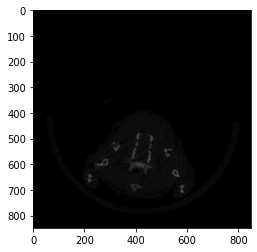

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5576/Brinp3_F_E64-G5576_Rec/Brinp3_F_E64-G5576__fantom2
END slice fantom2: Brinp3_F_E64-G5576__rec00000701.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1655
Count of head images: 531
Count of body images: 1181
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5577
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5577/Brinp3_F_E64-G5577_Rec
                               Image_name  Propability
0     Brinp3_F_E64-G5577__rec00000428.bmp     0.109385
1     Brinp3_F_E64-G5577__rec00000429.bmp     

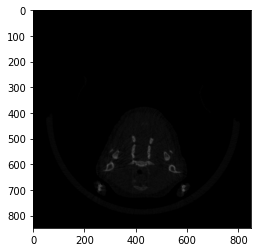

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5577/Brinp3_F_E64-G5577_Rec/Brinp3_F_E64-G5577__fantom2
END slice fantom2: Brinp3_F_E64-G5577__rec00000722.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1577
Count of head images: 540
Count of body images: 1103
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5581+
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5582
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp

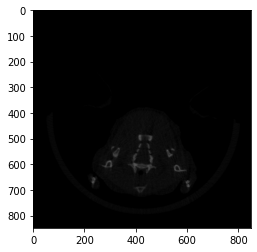

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5582/Brinp3_F_E64-G5582_Rec/Brinp3_F_E64-G5582__fantom2
END slice fantom2: Brinp3_F_E64-G5582__rec00000670.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1650
Count of head images: 549
Count of body images: 1176
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5598
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5598/Brinp3_F_E64-G5598_Rec
                               Image_name  Propability
0     Brinp3_F_E64-G5598__rec00000377.bmp     0.109172
1     Brinp3_F_E64-G5598__rec00000378.bmp     

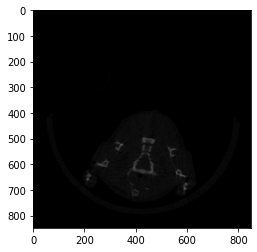

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5598/Brinp3_F_E64-G5598_Rec/Brinp3_F_E64-G5598__fantom2
END slice fantom2: Brinp3_F_E64-G5598__rec00000671.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1577
Count of head images: 543
Count of body images: 1103
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5599
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5599/Brinp3_F_E64-G5599_Rec
                               Image_name  Propability
0     Brinp3_F_E64-G5599__rec00000408.bmp     0.107024
1     Brinp3_F_E64-G5599__rec00000409.bmp     

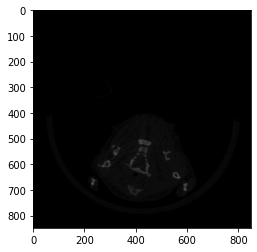

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5599/Brinp3_F_E64-G5599_Rec/Brinp3_F_E64-G5599__fantom2
END slice fantom2: Brinp3_F_E64-G5599__rec00000702.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1569
Count of head images: 517
Count of body images: 1095
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5600
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5600/Brinp3_F_E64-G5600_Rec
                               Image_name  Propability
0     Brinp3_F_E64-G5600__rec00000405.bmp     0.116247
1     Brinp3_F_E64-G5600__rec00000406.bmp     

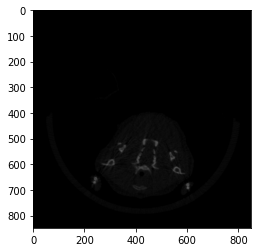

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5600/Brinp3_F_E64-G5600_Rec/Brinp3_F_E64-G5600__fantom2
END slice fantom2: Brinp3_F_E64-G5600__rec00000699.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1545
Count of head images: 562
Count of body images: 1071
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_M_E64-G5534
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_M_E64-G5534/Brinp3_M_E64-G5534_Rec
                               Image_name  Propability
0     Brinp3_M_E64-G5534__rec00000408.bmp     0.113165
1     Brinp3_M_E64-G5534__rec00000409.bmp     

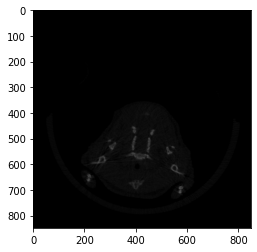

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_M_E64-G5534/Brinp3_M_E64-G5534_Rec/Brinp3_M_E64-G5534__fantom2
END slice fantom2: Brinp3_M_E64-G5534__rec00000702.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1640
Count of head images: 556
Count of body images: 1166
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_M_E64-G5541
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_M_E64-G5541/Brinp3_M_E64-G5541_Rec
                               Image_name  Propability
0     Brinp3_M_E64-G5541__rec00000370.bmp     0.111878
1     Brinp3_M_E64-G5541__rec00000371.bmp     

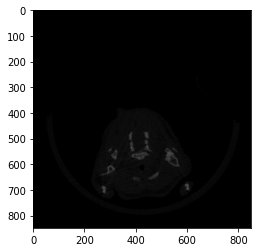

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_M_E64-G5541/Brinp3_M_E64-G5541_Rec/Brinp3_M_E64-G5541__fantom2
END slice fantom2: Brinp3_M_E64-G5541__rec00000664.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1656
Count of head images: 548
Count of body images: 1182
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_M_E64-G5570
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_M_E64-G5570/Brinp3_M_E64-G5570_Rec
                               Image_name  Propability
0     Brinp3_M_E64-G5570__rec00000386.bmp     0.118168
1     Brinp3_M_E64-G5570__rec00000387.bmp     

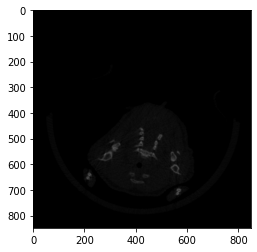

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_M_E64-G5570/Brinp3_M_E64-G5570_Rec/Brinp3_M_E64-G5570__fantom2
END slice fantom2: Brinp3_M_E64-G5570__rec00000680.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1666
Count of head images: 547
Count of body images: 1192
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_M_E64-G5573
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_M_E64-G5573/Brinp3_M_E64-G5573_Rec
                               Image_name  Propability
0     Brinp3_M_E64-G5573__rec00000405.bmp     0.112064
1     Brinp3_M_E64-G5573__rec00000406.bmp     

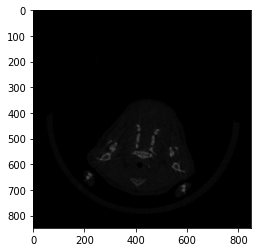

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_M_E64-G5573/Brinp3_M_E64-G5573_Rec/Brinp3_M_E64-G5573__fantom2
END slice fantom2: Brinp3_M_E64-G5573__rec00000694.bmp
Index of last fanrom2 image in the full data frame: Int64Index([289], dtype='int64')
Index of predicted head slice: 1615
Count of head images: 548
Count of body images: 1146
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_M_E64-G5579
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_M_E64-G5579/Brinp3_M_E64-G5579_Rec
                               Image_name  Propability
0     Brinp3_M_E64-G5579__rec00000382.bmp     0.109865
1     Brinp3_M_E64-G5579__rec00000383.bmp     

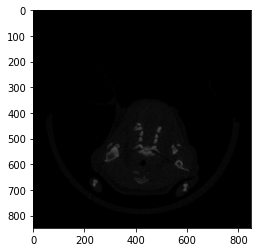

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_M_E64-G5579/Brinp3_M_E64-G5579_Rec/Brinp3_M_E64-G5579__fantom2
END slice fantom2: Brinp3_M_E64-G5579__rec00000676.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1688
Count of head images: 525
Count of body images: 1214
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_M_E64-G5595
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_M_E64-G5595/Brinp3_M_E64-G5595_Rec
                               Image_name  Propability
0     Brinp3_M_E64-G5595__rec00000386.bmp     0.121571
1     Brinp3_M_E64-G5595__rec00000387.bmp     

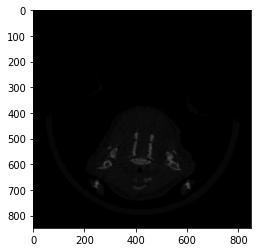

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_M_E64-G5595/Brinp3_M_E64-G5595_Rec/Brinp3_M_E64-G5595__fantom2
END slice fantom2: Brinp3_M_E64-G5595__rec00000680.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1630
Count of head images: 547
Count of body images: 1156
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_M_E64-G5596
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_M_E64-G5596/Brinp3_M_E64-G5596_Rec
                               Image_name  Propability
0     Brinp3_M_E64-G5596__rec00000399.bmp     0.117296
1     Brinp3_M_E64-G5596__rec00000400.bmp     

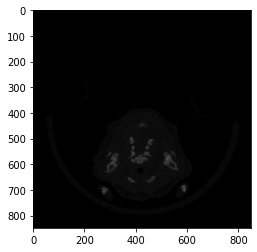

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_M_E64-G5596/Brinp3_M_E64-G5596_Rec/Brinp3_M_E64-G5596__fantom2
END slice fantom2: Brinp3_M_E64-G5596__rec00000688.bmp
Index of last fanrom2 image in the full data frame: Int64Index([289], dtype='int64')
Index of predicted head slice: 1619
Count of head images: 543
Count of body images: 1150
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_M_E64-G5597
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_M_E64-G5597/Brinp3_M_E64-G5597_Rec
                               Image_name  Propability
0     Brinp3_M_E64-G5597__rec00000380.bmp     0.109881
1     Brinp3_M_E64-G5597__rec00000381.bmp     

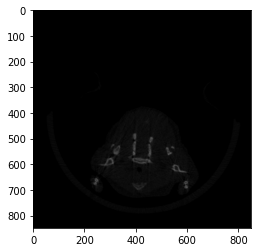

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_F_E64-G5481/Gm20219_F_E64-G5481_Rec/Gm20219_F_E64-G5481__fantom2
END slice fantom2: Gm20219_F_E64-G5481__rec00000690.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1537
Count of head images: 552
Count of body images: 1063
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_F_E64-G5482
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_F_E64-G5482/Gm20219_F_E64-G5482_Rec
                                Image_name  Propability
0     Gm20219_F_E64-G5482__rec00000398.bmp     0.103466
1     Gm20219_F_E64-G5482__rec0000039

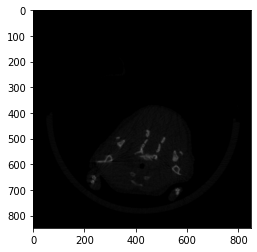

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_F_E64-G5482/Gm20219_F_E64-G5482_Rec/Gm20219_F_E64-G5482__fantom2
END slice fantom2: Gm20219_F_E64-G5482__rec00000692.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1615
Count of head images: 567
Count of body images: 1141
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_F_E64-G5489
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_F_E64-G5489/Gm20219_F_E64-G5489_Rec
                                Image_name  Propability
0     Gm20219_F_E64-G5489__rec00000391.bmp     0.102205
1     Gm20219_F_E64-G5489__rec0000039

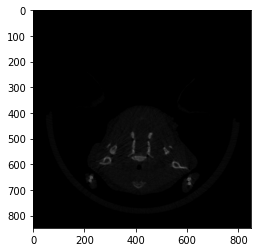

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_F_E64-G5489/Gm20219_F_E64-G5489_Rec/Gm20219_F_E64-G5489__fantom2
END slice fantom2: Gm20219_F_E64-G5489__rec00000685.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1634
Count of head images: 539
Count of body images: 1160
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_F_E64-G5490
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_F_E64-G5490/Gm20219_F_E64-G5490_Rec
                                Image_name  Propability
0     Gm20219_F_E64-G5490__rec00000403.bmp     0.108340
1     Gm20219_F_E64-G5490__rec0000040

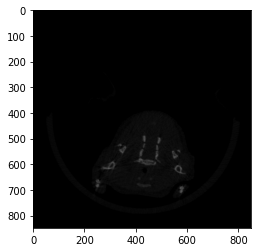

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_F_E64-G5490/Gm20219_F_E64-G5490_Rec/Gm20219_F_E64-G5490__fantom2
END slice fantom2: Gm20219_F_E64-G5490__rec00000697.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1563
Count of head images: 535
Count of body images: 1089
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_M_E64-G5488
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_M_E64-G5488/Gm20219_M_E64-G5488_Rec
                                Image_name  Propability
0     Gm20219_M_E64-G5488__rec00000370.bmp     0.109865
1     Gm20219_M_E64-G5488__rec0000037

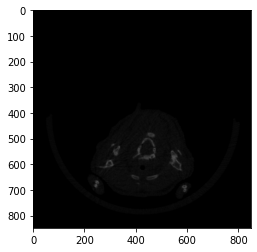

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_M_E64-G5488/Gm20219_M_E64-G5488_Rec/Gm20219_M_E64-G5488__fantom2
END slice fantom2: Gm20219_M_E64-G5488__rec00000664.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1655
Count of head images: 567
Count of body images: 1181
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_M_E64-G5492
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_M_E64-G5492/Gm20219_M_E64-G5492_Rec
                                Image_name  Propability
0     Gm20219_M_E64-G5492__rec00000355.bmp     0.106472
1     Gm20219_M_E64-G5492__rec0000035

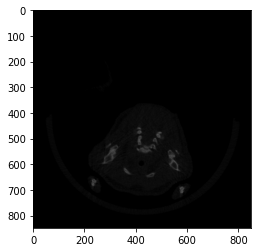

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_M_E64-G5492/Gm20219_M_E64-G5492_Rec/Gm20219_M_E64-G5492__fantom2
END slice fantom2: Gm20219_M_E64-G5492__rec00000649.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1774
Count of head images: 547
Count of body images: 1300
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_M_E64-G5493
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_M_E64-G5493/Gm20219_M_E64-G5493_Rec
                                Image_name  Propability
0     Gm20219_M_E64-G5493__rec00000376.bmp     0.116378
1     Gm20219_M_E64-G5493__rec0000037

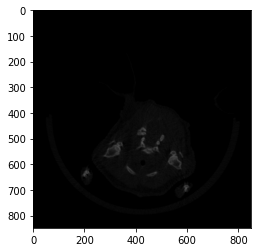

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_M_E64-G5493/Gm20219_M_E64-G5493_Rec/Gm20219_M_E64-G5493__fantom2
END slice fantom2: Gm20219_M_E64-G5493__rec00000665.bmp
Index of last fanrom2 image in the full data frame: Int64Index([289], dtype='int64')
Index of predicted head slice: 1730
Count of head images: 549
Count of body images: 1261
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_M_E64-G5496
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_M_E64-G5496/Gm20219_M_E64-G5496_Rec
                                Image_name  Propability
0     Gm20219_M_E64-G5496__rec00000403.bmp     0.107348
1     Gm20219_M_E64-G5496__rec0000040

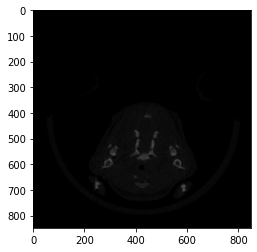

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_M_E64-G5496/Gm20219_M_E64-G5496_Rec/Gm20219_M_E64-G5496__fantom2
END slice fantom2: Gm20219_M_E64-G5496__rec00000675.bmp
Index of last fanrom2 image in the full data frame: Int64Index([272], dtype='int64')
Index of predicted head slice: 1638
Count of head images: 526
Count of body images: 1186
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_M_E64-G5503
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_M_E64-G5503/Gm20219_M_E64-G5503_Rec
                                Image_name  Propability
0     Gm20219_M_E64-G5503__rec00000345.bmp     0.111089
1     Gm20219_M_E64-G5503__rec0000034

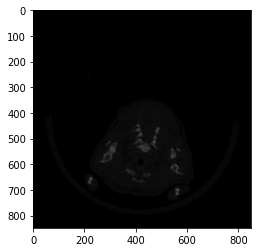

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_M_E64-G5503/Gm20219_M_E64-G5503_Rec/Gm20219_M_E64-G5503__fantom2
END slice fantom2: Gm20219_M_E64-G5503__rec00000639.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1840
Count of head images: 532
Count of body images: 1366
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_M_E64-G5511
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_M_E64-G5511/Gm20219_M_E64-G5511_Rec
                                Image_name  Propability
0     Gm20219_M_E64-G5511__rec00000372.bmp     0.105048
1     Gm20219_M_E64-G5511__rec0000037

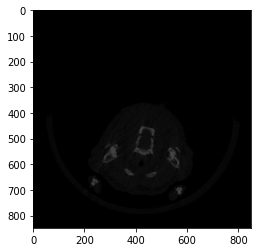

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_M_E64-G5511/Gm20219_M_E64-G5511_Rec/Gm20219_M_E64-G5511__fantom2
END slice fantom2: Gm20219_M_E64-G5511__rec00000666.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1701
Count of head images: 571
Count of body images: 1227
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_M_E64-G5513
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_M_E64-G5513/Gm20219_M_E64-G5513_Rec
                                Image_name  Propability
0     Gm20219_M_E64-G5513__rec00000357.bmp     0.112057
1     Gm20219_M_E64-G5513__rec0000035

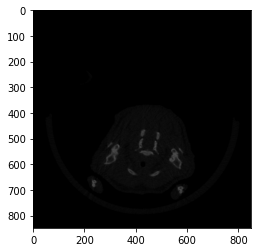

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_M_E64-G5513/Gm20219_M_E64-G5513_Rec/Gm20219_M_E64-G5513__fantom2
END slice fantom2: Gm20219_M_E64-G5513__rec00000651.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1753
Count of head images: 540
Count of body images: 1279
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_M_E64-G5515
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_M_E64-G5515/Gm20219_M_E64-G5515_Rec
                                Image_name  Propability
0     Gm20219_M_E64-G5515__rec00000368.bmp     0.110531
1     Gm20219_M_E64-G5515__rec0000036

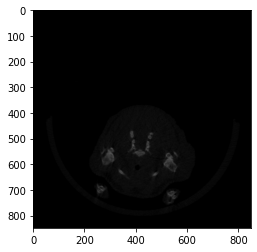

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Gm20219_M_E64-G5515/Gm20219_M_E64-G5515_Rec/Gm20219_M_E64-G5515__fantom2
END slice fantom2: Gm20219_M_E64-G5515__rec00000642.bmp
Index of last fanrom2 image in the full data frame: Int64Index([274], dtype='int64')
Index of predicted head slice: 1721
Count of head images: 552
Count of body images: 1267
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/wt_F_82Z-09602
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/wt_F_82Z-09602/wt_F_82Z-09602_Rec
                           Image_name  Propability
0     wt_F_82Z-09602__rec00000377.bmp     0.108047
1     wt_F_82Z-09602__rec00000378.bmp     0.108445
2     wt_F_

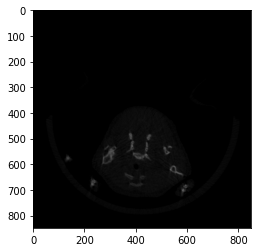

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/wt_F_82Z-09602/wt_F_82Z-09602_Rec/wt_F_82Z-09602__fantom2
END slice fantom2: wt_F_82Z-09602__rec00000671.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1641
Count of head images: 545
Count of body images: 1167
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/wt_F_82Z-09603
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/wt_F_82Z-09603/wt_F_82Z-09603_Rec
                           Image_name  Propability
0     wt_F_82Z-09603__rec00000403.bmp     0.106727
1     wt_F_82Z-09603__rec00000404.bmp     0.105187
2     wt_F_82Z-09603__rec000004

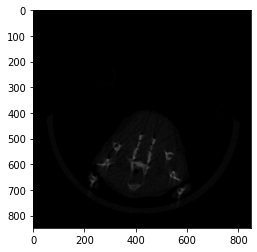

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/wt_F_82Z-09603/wt_F_82Z-09603_Rec/wt_F_82Z-09603__fantom2
END slice fantom2: wt_F_82Z-09603__rec00000697.bmp
Index of last fanrom2 image in the full data frame: Int64Index([294], dtype='int64')
Index of predicted head slice: 1604
Count of head images: 541
Count of body images: 1130
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/wt_F_82Z-09604
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/wt_F_82Z-09604/wt_F_82Z-09604_Rec
                           Image_name  Propability
0     wt_F_82Z-09604__rec00000400.bmp     0.113172
1     wt_F_82Z-09604__rec00000401.bmp     0.112844
2     wt_F_82Z-09604__rec000004

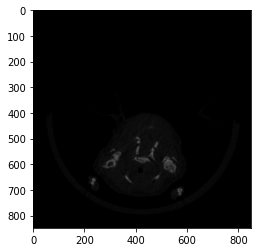

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/wt_F_82Z-09604/wt_F_82Z-09604_Rec/wt_F_82Z-09604__fantom2
END slice fantom2: wt_F_82Z-09604__rec00000661.bmp
Index of last fanrom2 image in the full data frame: Int64Index([261], dtype='int64')
Index of predicted head slice: 1698
Count of head images: 544
Count of body images: 1257
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/wt_M_82Z-09599
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/wt_M_82Z-09599/wt_M_82Z-09599_Rec
                           Image_name  Propability
0     wt_M_82Z-09599__rec00000326.bmp     0.104415
1     wt_M_82Z-09599__rec00000327.bmp     0.107570
2     wt_M_82Z-09599__rec000003

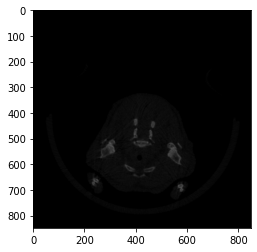

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/wt_M_82Z-09599/wt_M_82Z-09599_Rec/wt_M_82Z-09599__fantom2
END slice fantom2: wt_M_82Z-09599__rec00000590.bmp
Index of last fanrom2 image in the full data frame: Int64Index([264], dtype='int64')
Index of predicted head slice: 1936
Count of head images: 556
Count of body images: 1492
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/wt_M_82Z-09600
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/wt_M_82Z-09600/wt_M_82Z-09600_Rec
                           Image_name  Propability
0     wt_M_82Z-09600__rec00000417.bmp     0.114681
1     wt_M_82Z-09600__rec00000418.bmp     0.111782
2     wt_M_82Z-09600__rec000004

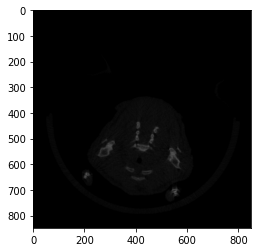

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/wt_M_82Z-09600/wt_M_82Z-09600_Rec/wt_M_82Z-09600__fantom2
END slice fantom2: wt_M_82Z-09600__rec00000677.bmp
Index of last fanrom2 image in the full data frame: Int64Index([260], dtype='int64')
Index of predicted head slice: 1631
Count of head images: 556
Count of body images: 1191
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/wt_M_82Z-09601
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/wt_M_82Z-09601/wt_M_82Z-09601_Rec
                           Image_name  Propability
0     wt_M_82Z-09601__rec00000390.bmp     0.108773
1     wt_M_82Z-09601__rec00000391.bmp     0.109329
2     wt_M_82Z-09601__rec000003

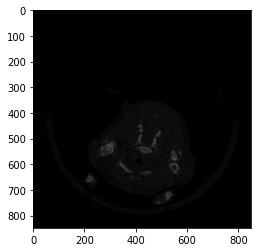

Path to the fantom2 folder: /home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/wt_M_82Z-09601/wt_M_82Z-09601_Rec/wt_M_82Z-09601__fantom2
END slice fantom2: wt_M_82Z-09601__rec00000674.bmp
Index of last fanrom2 image in the full data frame: Int64Index([284], dtype='int64')
Index of predicted head slice: 1659
Count of head images: 572
Count of body images: 1195
Folders were created
Images were copied to the new folders
Empty DataFrame
Columns: [Image_name, Propability]
Index: []
Empty DataFrame
Columns: [Image_name, Propability]
Index: []


In [25]:
#predict('/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20210830c204_Cd38 & Cnpy4 & Proser2 & Psen2 & wt/Cd38_F_E64-G1287/Cd38_F_E64-G1287_Rec')
predict(cohort_folder)

<span style="color:blue"><font size="5">Part 3: *function for masking body without head*</span>.

In [26]:
def masking_predict(parent):
    
    
    df = pd.DataFrame()
    #df_whole_mouse= pd.DataFrame(columns = ['Image_name'])
    
    result_names = []
    result_images = []
    values_pred =[]
    fantoms2 = []
    
    log=''
    log_file = ''
########################## READ IMAGES ##########################################    
    # iterate over all the files in directory 'parent'
    for file_name in sorted(os.listdir(parent)):
         # to have the ID of the mouse for creating the folder name 
        if file_name.endswith("__fantom1") or file_name.endswith("__fantom2")  or file_name.startswith("Morphology") or file_name.endswith("__without_fantoms") or file_name.endswith("__head")or file_name.endswith("__mask"):
            # skip directories
            continue

        
        if file_name.endswith('__body'):
            
            current_path = "".join((parent,'/', file_name))
            print(current_path)
            df=creat_dataframe(current_path)
            df=df.sort_values(by=['id'])
            df = df.reset_index(drop=True)
            val_dataset = get_validation_dataset(df)
            preds=loaded_model_masking.predict(val_dataset)
            
            id_mouse= df.id[0].split('rec')[0]
            path_to_save_mask = "".join((parent,'/', id_mouse,'mask'))
            print(path_to_save_mask)
            os.mkdir(path_to_save_mask)

            for i in range(len(preds)):
                th, im_th = cv2.threshold(preds[i], 0.1, 255, cv2.THRESH_BINARY)
                im = cv2.resize(im_th, (848, 848))
                im = im.astype(np.uint8)
                #print(im.shape)
                cv2.imwrite(path_to_save_mask+'/'+df['id'][i]+'.bmp',im)  
                
    
            
            ##############
            path_to_save_mask_edit = "".join((parent,'/', id_mouse,'mask_edited'))
            os.mkdir(path_to_save_mask_edit)
            print(path_to_save_mask_edit)
            
            for i in range(len(preds)):
                array_mask=cv2.imread(path_to_save_mask+'/'+df.id[i]+'.bmp',cv2.COLOR_BGR2GRAY)
                #array_mask = cv2.imread('/home/potip/PRIMUS/data/83_BIOINFORMATICS/Julia/cohort_full/predicted/Cops8_M_E64-G2107__rec00001675.bmp')
                contours, hierarchy= cv2.findContours(array_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

                sorted_contours= sorted(contours, key=cv2.contourArea, reverse= True)
                array_len=[]
                
                for s in sorted_contours:
                    #find=sorted_contours[i]
                    len_s=len(s)
                    array_len.append(len_s)
                #print(array_len)
                
                if len(array_len)<=1:
                    array_mask=array_mask.astype(np.uint8)
                    cv2.imwrite(path_to_save_mask_edit+'/'+df.id[i]+'.bmp',array_mask)
                    
                while len(sorted_contours)>1:
                    #print(len(sorted_contours))
                    #print(df.id[i])
                    result=cv2.fillConvexPoly(array_mask, np.array(sorted_contours[1], 'int32'), 0)
                    result=np.uint8(result)
                    #print(result.shape)
                    contours, hierarchy= cv2.findContours(array_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
                    sorted_contours= sorted(contours, key=cv2.contourArea, reverse= True)
                    cv2.imwrite(path_to_save_mask_edit+'/'+df.id[i]+'.bmp',result)
                
                ################
                
            path_images_body = "".join((parent,'/', file_name))
            path_to_save_predictions = "".join((parent,'/', id_mouse,'predictions'))
            os.mkdir(path_to_save_predictions)
            print(path_to_save_predictions)  
        
            for i in range(len(preds)):
                image=cv2.imread(path_images_body+'/'+df.id[i]+'.bmp',cv2.IMREAD_GRAYSCALE)
                mask=cv2.imread(path_to_save_mask_edit+'/'+df.id[i]+'.bmp',cv2.IMREAD_GRAYSCALE)
                result = cv2.bitwise_and(image, mask)
                #print(result.shape)
                cv2.imwrite(path_to_save_predictions+'/'+df.id[i]+'.bmp',result)
                
            log='rec.log'
            log_file = id_mouse + log    
            shutil.copy(os.path.join(parent, log_file), path_to_save_predictions)
            
            #delete mask folder for the first masks
            shutil.rmtree(path_to_save_mask)
            print("Old folder with masks was deleted:", path_to_save_mask)

        else:
            current_path = "".join((parent,'/', file_name))
            if os.path.isdir(current_path):
                print(current_path)
                masking_predict(current_path)
            else:
                continue
                

In [27]:
#masking_predict('/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220110c222_Atp1a1 & Irak4 & Kcnn4 & Krt1 & Tmprss2 & Ube3a & wt/Atp1a1_F_E64-G3789/Atp1a1_F_E64-G3789_Rec')
#masking_predict(cohort_folder+'/wt_F_82Z-09261')
masking_predict(cohort_folder)

/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5557+
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5576
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5576/Brinp3_F_E64-G5576_Rec
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5576/Brinp3_F_E64-G5576_Rec/Brinp3_F_E64-G5576__body
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5576/Brinp3_F_E64-G5576_Rec/Brinp3_F_E64-G5576__mask
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5576/Brinp3_F_E64-G5576_Rec/Brinp3_F_E64-G5576__mask_edited
/home/potip/PRIMUS/data/83_IMPC_DATA/Bi

<span style="color:blue"><font size="5">Part 4: *function for masking fantoms to get ROI*</span>.

In [28]:
def mask_fantoms(parent):
    
    log=''
    log_file = ''
########################## READ IMAGES ##########################################    
    # iterate over all the files in directory 'parent'
    for file_name in sorted(os.listdir(parent)):
         # to have the ID of the mouse for creating the folder name 
        if file_name.endswith("__without_fantoms") or file_name.endswith("__holder") or  file_name.endswith("__head")or file_name.endswith("__body") or file_name.startswith("Morphology") or file_name.endswith("__mask_edited") or file_name.endswith("__predictions"):
            # skip directories
            continue
            ######## Fantom 1 ###############
        if file_name.endswith('__fantom1'):
            current_path = "".join((parent,'/', file_name))
            print(current_path)
            id_mouse = file_name.split("__fantom1")[0]
            
            fantom1_path = "".join((parent,'/', id_mouse,'__fantom1'))  
            
            print(id_mouse)
            df=creat_dataframe(current_path)
            df=df.sort_values(by=['id'])
            
            path_to_mask_fantom1 = "".join((fantom1_path,'/',id_mouse, '__fantom1_mask'))
            os.mkdir(path_to_mask_fantom1)
            
            
            path_to_ROI_fantom1 = "".join((fantom1_path,'/',id_mouse, '__fantom1_ROI'))
            os.mkdir(path_to_ROI_fantom1)
           
            
            for i in range(len(df)):
                image=cv2.imread(fantom1_path+'/'+df.id[i]+'.bmp',cv2.COLOR_BGR2GRAY)
                min_val, max_val, min_indx, max_indx =cv2.minMaxLoc(image)
                blurred = cv2.GaussianBlur(image, (11, 11), 0)
                mask = cv2.threshold(blurred,max_val-10, 255, cv2.THRESH_BINARY)[1]


                cv2.imwrite(path_to_mask_fantom1+'/'+df.id[i]+'.bmp',mask)

                image=cv2.imread(fantom1_path+'/'+df.id[i]+'.bmp',cv2.COLOR_BGR2GRAY)
                mask=cv2.imread(path_to_mask_fantom1+'/'+df.id[i]+'.bmp',cv2.COLOR_BGR2GRAY)
                result = cv2.bitwise_and(image, mask)


                cv2.imwrite(path_to_ROI_fantom1+'/'+df.id[i]+'.bmp',result)
                
                log='__rec.log'
                log_file = id_mouse + log    
                shutil.copy(os.path.join(parent, log_file), path_to_ROI_fantom1)
            
            ########### Fantom 2 ##################
            fantom2_path = "".join((parent,'/', id_mouse,'__fantom2'))  
            print(fantom2_path)
            df=creat_dataframe(fantom2_path)
            df=df.sort_values(by=['id'])

            path_to_mask_fantom2 = "".join((fantom2_path,'/',id_mouse, '__fantom2_mask'))
            os.mkdir(path_to_mask_fantom2)
           

            path_to_ROI_fantom2 = "".join((fantom2_path,'/',id_mouse, '__fantom2_ROI'))
            os.mkdir(path_to_ROI_fantom2)
            
            
           

            for i in range(len(df)):
                image=cv2.imread(fantom2_path+'/'+df.id[i]+'.bmp',cv2.COLOR_BGR2GRAY)
                min_val, max_val, min_indx, max_indx =cv2.minMaxLoc(image)
                blurred = cv2.GaussianBlur(image, (11, 11), 0)
                mask = cv2.threshold(blurred,max_val-10, 255, cv2.THRESH_BINARY)[1]


                cv2.imwrite(path_to_mask_fantom2+'/'+df.id[i]+'.bmp',mask)

                image=cv2.imread(fantom2_path+'/'+df.id[i]+'.bmp',cv2.COLOR_BGR2GRAY)
                mask=cv2.imread(path_to_mask_fantom2+'/'+df.id[i]+'.bmp',cv2.COLOR_BGR2GRAY)
                result = cv2.bitwise_and(image, mask)


                cv2.imwrite(path_to_ROI_fantom2+'/'+df.id[i]+'.bmp',result)
                log='__rec.log'
                log_file = id_mouse + log    
                shutil.copy(os.path.join(parent, log_file), path_to_ROI_fantom2)
        
        
        
        
        else:
            current_path = "".join((parent,'/', file_name))
            if os.path.isdir(current_path):
                print(current_path)
                mask_fantoms(current_path)
            else:
                continue
            
            
            


In [ ]:
#mask_fantoms('/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220110c222_Atp1a1 & Irak4 & Kcnn4 & Krt1 & Tmprss2 & Ube3a & wt/Atp1a1_F_E64-G3789/Atp1a1_F_E64-G3789_Rec')
mask_fantoms(cohort_folder)

/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5557+
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5576
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5576/Brinp3_F_E64-G5576_Rec
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5576/Brinp3_F_E64-G5576_Rec/Brinp3_F_E64-G5576__fantom1
Brinp3_F_E64-G5576
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5576/Brinp3_F_E64-G5576_Rec/Brinp3_F_E64-G5576__fantom2
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220404c233_Brinp3 & Tincr & wt/Brinp3_F_E64-G5576/Brinp3_F_E64-G5576_Rec/Brinp3_F_E64-G5576__fantom2
/home/potip/PRIMUS

<span style="color:blue"><font size="5">Part 5: *function for BMD and TMD calculation*</span>.

In [10]:
def TMD_BMD_AU(parent):
    
    df_BMD_TMD = pd.DataFrame()
    
    list_coef14 = []
    list_coef30 = []
    list_coeffantom1 = []
    list_coeffantom2 = []
    list_ID = []
    list_ID_without = []

    
    for_df_BMD_TMD = []
    
    for file_name in sorted(os.listdir(parent)):
         # to have the ID of the mouse for creating the folder name 
        if file_name.endswith("__fantom1") or file_name.startswith("Wdr63") or file_name.startswith("Apobec1") or file_name.startswith("Cactin") or file_name.startswith("phantom") or file_name.startswith("Cops8") or file_name.startswith("Pank2") or file_name.endswith("__fantom2") or file_name.endswith("_Rec2") or file_name.endswith("BMD_TMD") or file_name.endswith("+") or  file_name.endswith("!") or file_name.endswith("__predictions") or file_name.startswith("masks") or file_name.startswith("Morphology") or file_name.endswith("predictions") or file_name.endswith("__holder")  or file_name.endswith("__without_fantoms") or file_name.endswith("__head")or file_name.endswith("__mask") or file_name.endswith("__mask_edited") or file_name.endswith("__body"):
            # skip directories
            continue   
        
        if file_name in ( 'wt_F_82Z-09089', 'wt_F_82Z-09090'):
            continue
    
        if file_name.endswith('_Rec'):# in future '__predictions'
            id_mouse = file_name.split("_Rec")[0]
            print(id_mouse)
            list_ID.append(id_mouse)
                
            id_mouse_without = id_mouse.split('_')[-1]
            print(id_mouse_without)
            list_ID_without.append(id_mouse_without)
          
            fantom1_path="".join((parent,'/', id_mouse,'_Rec','/', id_mouse,'__fantom1','/',id_mouse,'__fantom1_ROI'))
            fantom2_path="".join((parent,'/', id_mouse,'_Rec','/', id_mouse,'__fantom2','/',id_mouse,'__fantom2_ROI'))
            body_path="".join((parent,'/', id_mouse,'_Rec','/',id_mouse,'__predictions'))
            print(body_path)
            ###### BODY Coef14 ##############
            for file_name in sorted(os.listdir(body_path)):
                if file_name.endswith('.bmp'):
                    #print(file_name)
                    array_mask = cv2.imread(body_path+'/'+file_name,cv2.IMREAD_GRAYSCALE)
                    coef14=array_mask[array_mask>=13]
                    if coef14.size > 0:
                        list_coef14=np.concatenate((list_coef14, coef14), axis=None)
        
        
           
            ############# FANTOM1 Coef ##############            
            for file_name in sorted(os.listdir(fantom1_path)):
                if file_name.endswith('.bmp'):
                    array_mask = cv2.imread(fantom1_path+'/'+file_name,cv2.IMREAD_GRAYSCALE)
                    coeffantom1=array_mask[array_mask>0]
                    #print(coeffantom1)
                    if coeffantom1.size > 0:
                        list_coeffantom1=np.concatenate((list_coeffantom1, coeffantom1), axis=None)
                        
               
                        
            ############## FANTOM2 Coef ##############              
            for file_name in sorted(os.listdir(fantom2_path)):
                if file_name.endswith('.bmp'):
                    array_mask = cv2.imread(fantom2_path+'/'+file_name,cv2.IMREAD_GRAYSCALE)
                    coeffantom2=array_mask[array_mask>0]
                    #print(coeffantom2)
                    if coeffantom2.size > 0:
                        list_coeffantom2=np.concatenate((list_coeffantom2, coeffantom2), axis=None)
                        
                      
           
        else:
            current_path = "".join((parent,'/', file_name))
            if os.path.isdir(current_path):
                print(current_path)
                TMD_BMD_AU(current_path)
            else:
                continue
                
    # we need this shift
    #print(len(list_coef14))
    if len(list_coef14)>0:
        list_coef14=list_coef14+1
    
        list_coef30 = list_coef14[list_coef14>=30]
    
        mean_fantom1 = np.mean(list_coeffantom1)
        mean_fantom2 = np.mean(list_coeffantom2)
        mean_coef14 = np.mean(list_coef14)
        mean_coef30 = np.mean(list_coef30)


        AUcoeffantom1=(0.00038235294118*mean_fantom1) + 0.0025
        AUcoeffantom2=(0.00038235294118*mean_fantom2) + 0.0025
        AUcoef14=(0.00038235294118*mean_coef14) + 0.0025
        AUcoef30=(0.00038235294118*mean_coef30) + 0.0025

        slope = (AUcoeffantom2 - AUcoeffantom1)/50
        HAP00 = AUcoeffantom1 - (slope*25)
        TMD = (AUcoef30 - HAP00)/(100*slope)
        BMD = (AUcoef14 - HAP00)/(100*slope)


        #print(mean_fantom1, mean_fantom2, mean_coef14, mean_coef30)
        print(AUcoeffantom1, AUcoeffantom2, AUcoef14, AUcoef30)
        print(BMD,TMD)


        for file_name in sorted(os.listdir(parent))[:5]:
            if file_name.endswith('.tif'):
                print(file_name)
                created = os.stat(parent+'/'+ file_name).st_ctime
                print(created)
                created = datetime.fromtimestamp(created)
                print(created)
                only_date, only_time = created.date(), created.time()
                print(file_name, only_date)

        if list_ID and BMD and TMD:
            for_df_BMD_TMD.append(list_ID_without[0])
            print(only_date)
            for_df_BMD_TMD.append(only_date)
            for_df_BMD_TMD.append('UCT 0241')
            for_df_BMD_TMD.append(TMD)
            for_df_BMD_TMD.append(BMD)

            df_BMD_TMD = df_BMD_TMD.append(pd.DataFrame([for_df_BMD_TMD], columns = ['CCP_mouseID','CCP_date','CCP_metadata','CCP_DXA_793_001', 'CCP_DXA_004_001']), ignore_index=True)
            #print(AU_fantom1)
            df_BMD_TMD.to_csv(cohort_folder+'/'+'BMD_TMD'+'/'+list_ID[0]+'.csv') 
            print(parent+'/'+list_ID[0]+'.csv')
    else:
        print('ERROR!!!! NO Data for Analysis! Look into the folder!')
    

In [11]:

isBMD_TMD = os.path.exists(cohort_folder+'/'+'BMD_TMD')

if not isBMD_TMD:
  # Create a new directory because it does not exist 
    os.mkdir(cohort_folder+'/'+'BMD_TMD')

TMD_BMD_AU(cohort_folder)


/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220214c227_Apobec1 & Cactin & Cops8 & Pank2 & Wdr63 & wt/wt_F_82Z-09138
wt_F_82Z-09138
82Z-09138
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220214c227_Apobec1 & Cactin & Cops8 & Pank2 & Wdr63 & wt/wt_F_82Z-09138/wt_F_82Z-09138_Rec/wt_F_82Z-09138__predictions
0.015573707643514092 0.03185185278122264 0.009797688963899924 0.02172604366724061
0.07258363496729305 0.43897533999357663
wt_F_82Z-09138_~0000000000.tif
1644836277.7058284
2022-02-14 11:57:57.705828
wt_F_82Z-09138_~0000000000.tif 2022-02-14
2022-02-14
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220214c227_Apobec1 & Cactin & Cops8 & Pank2 & Wdr63 & wt/wt_F_82Z-09138/wt_F_82Z-09138.csv
/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp/Screen20220214c227_Apobec1 & Cactin & Cops8 & Pank2 & Wdr63 & wt/wt_F_82Z-09139
wt_F_82Z-09139
82Z-09139
/home/potip/PRIMUS/d

KeyboardInterrupt: 

In [14]:

all_files = glob.glob(os.path.join(cohort_folder+'/'+'BMD_TMD', "*.csv"))
df_from_each_file = (pd.read_csv(f, sep=',',header=0) for f in all_files)
df_merged = pd.concat(df_from_each_file, ignore_index=True)

df_merged.drop(df_merged.filter(regex="Unname"),axis=1, inplace=True)
df_merged = df_merged.sort_values(by='CCP_mouseID')
df_merged = df_merged.reset_index(drop=True)
df_merged.rename(columns = {'CCP_mouseID':'Identificator','CCP_date':'CCP_DXA_001', 'CCP_metadata':'','CCP_DXA_793_001':'','CCP_DXA_004_001':''}, inplace = True)
df_merged.loc[-1] = ['CCP_mouseID','CCP_date', 'CCP_metadata','CCP_DXA_793_001','CCP_DXA_004_001']
df_merged.index = df_merged.index + 1
df_merged.loc[-1] = ['MouseID','Date', 'MetaDatalink','TMD','BMD']
df_merged.index = df_merged.index + 1
df_merged = df_merged.sort_index()
print(df_merged)
df_merged.to_excel(cohort_folder+'/'+'DXA '+cohort_number+'.xlsx',index=False,index_label=False)
#shutil.rmtree(cohort_folder+'/'+'BMD_TMD')

   Identificator CCP_DXA_001                                                
0        MouseID        Date  MetaDatalink              TMD              BMD
1    CCP_mouseID    CCP_date  CCP_metadata  CCP_DXA_793_001  CCP_DXA_004_001
2      82Z-09390  2022-03-15      UCT 0241          0.44985         0.072931
3      82Z-09391  2022-03-15      UCT 0241         0.433277         0.070172
4      82Z-09392  2022-03-15      UCT 0241         0.430413         0.070854
5      82Z-09395  2022-03-15      UCT 0241         0.441092         0.077285
6      82Z-09396  2022-03-15      UCT 0241         0.451345         0.076811
7      82Z-09397  2022-03-15      UCT 0241         0.453082         0.078066
8      82Z-09418  2022-03-15      UCT 0241         0.430082         0.065651
9      82Z-09419  2022-03-15      UCT 0241         0.454273         0.067602
10     82Z-09420  2022-03-15      UCT 0241         0.447262         0.068897
11     82Z-09421  2022-03-15      UCT 0241         0.453811         0.070733

<span style="color:blue"><font size="5">Part 6: *Connect to the DB to check SACRIFICE*</span>.

In [16]:
# connect to the DB
conn = mysql.connector.connect(host='london02.img.local', port=3306, database='vestlontest', user='vestlontest_bi', password='vJPeF5T6a83j$w8N')
cursor = conn.cursor()
sql= "SELECT * FROM MOUSE WHERE COHORT_ID ='%s'"%(cohort_number)
cursor.execute(sql)
database=pd.DataFrame(cursor.fetchall(),columns=['DOB','ID','SACRIFICE', 'LAB_ID', 'COHORT_ID','CAGE_ID'])
cursor.close()

# Read the excel file
sheet1_df = pd.read_excel(cohort_folder+'/'+'DXA '+cohort_number+'.xlsx')

# transform DF
excel_transf = sheet1_df[['Identificator', 'CCP_DXA_001']][2:]
excel_transf = excel_transf.reset_index(drop=True)
excel_transf=excel_transf.rename(columns={"Identificator":"ID", 'CCP_DXA_001':'Folder_date'})

#transform database table
database = database.sort_values(by='ID')
database = database[['ID','SACRIFICE']]

#find ids that are not in excel table
died=database['ID'][~database['ID'].isin(excel_transf['ID'])].dropna()
died = died.tolist()
for idd in died:
    new_row = {'Identificator':idd, 'CCP_DXA_001':'2021-12-13', 'Unnamed: 2':'UCT 0241', 'Unnamed: 3':'IMPC_PSC_001', 'Unnamed: 4':'IMPC_PSC_001'}
    sheet1_df = sheet1_df.append(new_row, ignore_index=True)
    
# add ids with code    
sheet1_df = sheet1_df[2:].sort_values(by='Identificator')
sheet1_df = sheet1_df.reset_index()
sheet1_df.pop('index')
sheet1_df.loc[-1] = ['CCP_mouseID','CCP_date', 'CCP_metadata','CCP_DXA_793_001','CCP_DXA_004_001']
sheet1_df.index = sheet1_df.index + 1
sheet1_df.loc[-1] = ['MouseID','Date', 'MetaDatalink','TMD','BMD']
sheet1_df.index = sheet1_df.index + 1
sheet1_df = sheet1_df.sort_index()
sheet1_df=sheet1_df.rename(columns={"Unnamed: 2":" ", 'Unnamed: 3':'', 'Unnamed: 4':''})

Python_version = !python -V

# Create DataFrame
sheet2_df = pd.DataFrame({'MetaData':['CCP_metadata', 'UCT 0241'], 
                          'Date equipment last calibrated':['CCP_DXA_017_001', excel_transf['Folder_date'][0]],
                          'Operator: Rec':['CCP_DXA_999_000', 'DXA_sfw_009'],
                          'Operator: ROI':['CCP_DXA_016_001', 'DXA_sfw_009'],
                          'Operator: BMD':['CCP_DXA_996_000', 'DXA_sfw_009'],
                          'Equipment ID':['CCP_DXA_011_001', '19G14030'],
                          'Equipment manufacturer':['CCP_DXA_012_001', 'Bruker'],
                          'Equipment model':['CCP_DXA_013_001', 'UCT 0241'],
                          'Mouse Status':['CCP_DXA_014_001', 'Anesthetized'],
                          'Anesthesia':['CCP_DXA_015_001', 'Zoletil+Xylazine'],
                          'DXA_Analytical software producer':['CCP_DXA_993_001', 'Python Software Foundation'],
                          'DXA_Analytical software':['CCP_DXA_992_001', 'Python'],
                          'DXA_Analytical software version':['CCP_DXA_991_001', Python_version[0]]})

print(database)
#with pd.ExcelWriter('/home/potip/PRIMUS/data/83_IMPC_DATA/Bioimaging/STATISTICS/_FINISHED_ Tabs_'+'/'+'DXA '+cohort_number+'.xlsx') as writer:
    #sheet1_df.to_excel(writer,sheet_name="Sheet1",index=False,index_label=False)
    #sheet2_df.to_excel(writer,sheet_name="Sheet2",index=False,index_label=False)

           ID   SACRIFICE
0   82Z-09390  2022-03-17
1   82Z-09391  2022-03-28
2   82Z-09392  2022-03-28
3   82Z-09395  2022-03-28
4   82Z-09396  2022-03-28
5   82Z-09397  2022-03-29
6   82Z-09418  2022-03-30
7   82Z-09419  2022-03-29
8   82Z-09420  2022-03-29
9   82Z-09421  2022-03-31
10  82Z-09432  2022-03-30
11  82Z-09433  2022-03-30
12  82Z-09434  2022-03-31
13  82Z-09435  2022-03-31
14  E64-G5020  2022-03-30
15  E64-G5024  2022-03-30
16  E64-G5025  2022-03-28
17  E64-G5026  2022-03-28
18  E64-G5027  2022-03-28
19  E64-G5028  2022-03-28
20  E64-G5029  2022-03-28
21  E64-G5030  2022-03-30
22  E64-G5032  2022-03-28
23  E64-G5084  2022-03-29
24  E64-G5085  2022-03-30
25  E64-G5086  2022-03-30
26  E64-G5095  2022-03-31
27  E64-G5096  2022-03-31
28  E64-G5097  2022-03-03
29  E64-G5098  2022-03-29
30  E64-G5099  2022-03-29
31  E64-G5100  2022-03-31
32  E64-G5101  2022-03-31
33  E64-G5102  2022-03-30
34  E64-G5103  2022-03-30
35  E64-G5104  2022-03-30
36  E64-G5105  2022-03-29
37  E64-G510